In [1]:
#导入相关库
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import rcParams

In [2]:
#设置中文字体
import matplotlib
matplotlib.rc("font", family = 'Microsoft Yahei')

In [3]:
# 读取后续分析需要的字段，控制内存占用

orders = pd.read_csv(
    "Dataset_Customer/orders.csv",
    usecols=[
        "order_id",
        "customer_id",
        "order_status",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

customers = pd.read_csv(
    "Dataset_Customer/customers.csv",
    usecols=[
        "customer_id",
        "customer_unique_id",
        "customer_city",
        "customer_state",
        "customer_segment"
    ]
)

payments = pd.read_csv(
    "Dataset_Customer/order_payments.csv",
    usecols=[
        "order_id",
        "payment_sequential",
        "payment_type",
        "payment_value"
    ]
)

print("数据读取成功")

for name, data in {
    "orders": orders,
    "customers": customers,
    "payments": payments
}.items():
    print(f"{name}: {data.shape}")

数据读取成功
orders: (1000000, 6)
customers: (1000000, 5)
payments: (1149371, 4)


In [4]:
# 构建已完成订单的一单一行核心行为表
# 1. 仅保留已完成订单，避免取消订单的支付金额污染 GMV、LTV 与 AOV
valid_order_status = 'delivered'
valid_orders = orders.loc[
    orders['order_status'].eq(valid_order_status),
    ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp']
].copy()
print(f"保留已完成订单：{len(valid_orders):,} 笔；筛除取消订单：{len(orders) - len(valid_orders):,} 笔")

# 2. 支付明细先聚合至订单粒度，确保每个 order_id 只有一行
# payment_value 为同一订单所有支付记录之和，适用于订单级 GMV、LTV 和 AOV 计算
# 不按 payment_value 去重：相同金额但不同 payment_sequential 的分笔支付均为有效支付。
payment_by_order = (
    payments.groupby('order_id', as_index=False)
    .agg(
        payment_value=('payment_value', 'sum'),
        payment_record_count=('payment_sequential', 'count')
    )
)
print(f"支付记录：{len(payments):,} 行；聚合后订单支付记录：{len(payment_by_order):,} 行")
print(f"存在多笔支付的订单数：{(payment_by_order['payment_record_count'] > 1).sum():,} 笔")

# 3. 使用一对一关联校验，防止支付明细或客户表的重复记录放大订单金额
order_level_df = valid_orders.merge(
    customers,
    on='customer_id',
    how='left',
    validate='one_to_one'
).merge(
    payment_by_order,
    on='order_id',
    how='left',
    validate='one_to_one'
)

# 每行代表一笔已完成订单，后续用户和金额指标均基于统一订单粒度
user_behavior_df = order_level_df[
    ['customer_unique_id', 'order_id', 'order_purchase_timestamp', 'payment_value']
].copy()

print("核心行为表（已完成订单，一单一行）")
print(user_behavior_df.head())
print("核心行为表形状：", user_behavior_df.shape)
print("去重订单数：", user_behavior_df['order_id'].nunique())
# 后续指标只使用 user_behavior_df；释放关联中间表以降低内存占用。
del valid_orders, payment_by_order, order_level_df


保留已完成订单：933,748 笔；筛除取消订单：66,252 笔
支付记录：1,149,371 行；聚合后订单支付记录：1,000,000 行
存在多笔支付的订单数：149,371 笔
核心行为表（已完成订单，一单一行）
                     customer_unique_id                              order_id  \
0  35cee471-325e-4ad2-8e4e-7b169dc6df81  c0142972-63fa-4af2-8070-f583ab769847   
1  c820d3a4-edd4-4b32-9605-22d97dcc8e5e  11bdf634-2b87-4d37-8d76-be1e7aff8f3b   
2  d3d86bff-2f03-4bec-9cbf-9a2f8f0d5783  d29b58ad-af2a-47b4-9214-b2664fb1fdba   
3  d2a156ae-a5ae-47df-81c3-19a9cb7df538  3d4a035e-588c-4ebd-ab6c-bf06a38cff10   
4  f2be528f-9b0d-4783-9389-2b44e52fb708  d7537ba2-da79-4a25-abaa-0b9a28452645   

  order_purchase_timestamp  payment_value  
0      2019-06-07 19:30:44        1406.07  
1      2023-04-02 14:39:33        1511.87  
2      2023-01-28 12:09:24         326.07  
3      2022-01-20 17:39:58         337.22  
4      2021-12-04 09:44:26         944.68  
核心行为表形状： (933748, 4)
去重订单数： 933748


In [5]:
# 缺失值处理：仅检查订单级核心字段
required_columns = [
    'customer_unique_id',
    'order_id',
    'order_purchase_timestamp',
    'payment_value'
]
print("缺失值个数：")
print(user_behavior_df[required_columns].isnull().sum())
user_behavior_df = user_behavior_df.dropna(subset=required_columns).copy()
print("去除缺失值后：")
print(user_behavior_df[required_columns].isnull().sum())


缺失值个数：
customer_unique_id          0
order_id                    0
order_purchase_timestamp    0
payment_value               0
dtype: int64
去除缺失值后：
customer_unique_id          0
order_id                    0
order_purchase_timestamp    0
payment_value               0
dtype: int64


In [6]:
# 订单粒度校验：核心行为表必须一单一行，不再按支付明细行去重
duplicate_order_count = user_behavior_df['order_id'].duplicated().sum()
print(f"重复订单数：{duplicate_order_count}")
assert duplicate_order_count == 0, "发现重复订单，请检查订单与支付表的关联粒度。"
print("订单粒度校验通过：每个 order_id 仅保留一行。")


重复订单数：0
订单粒度校验通过：每个 order_id 仅保留一行。


In [7]:
# 时间特征处理
# 将时间戳转换成日期格式
user_behavior_df['order_purchase_timestamp'] = pd.to_datetime(user_behavior_df['order_purchase_timestamp'])

# 提取相关的时间特征
# 日
user_behavior_df['order_date'] = user_behavior_df['order_purchase_timestamp'].dt.date

# 周
user_behavior_df['order_week'] = user_behavior_df['order_purchase_timestamp'].dt.to_period('W')

# 月
user_behavior_df['order_month'] = user_behavior_df['order_purchase_timestamp'].dt.to_period('M')

# 查看数据合并并清洗后的字段名
print("数据合并并清洗后的字段名")
print(user_behavior_df.columns)

数据合并并清洗后的字段名
Index(['customer_unique_id', 'order_id', 'order_purchase_timestamp',
       'payment_value', 'order_date', 'order_week', 'order_month'],
      dtype='object')


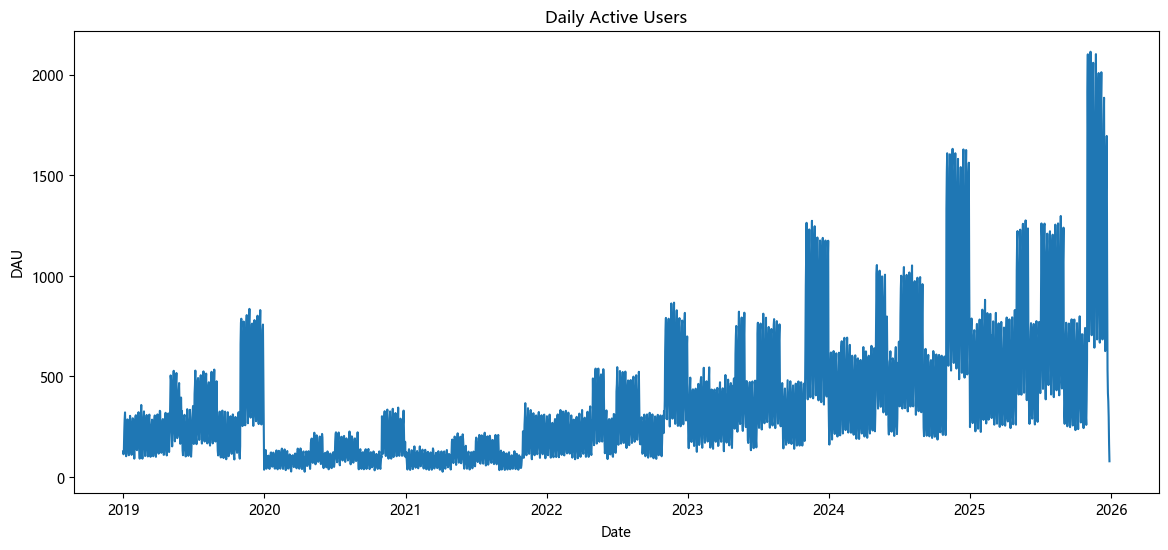

In [8]:
# DAU
# 计算DAU，并按日期排序（关键一步）
DAU = (user_behavior_df.groupby('order_date')['customer_unique_id']
       .nunique()
       .sort_index())

# DAU可视化
plt.figure(figsize=(14, 6))
plt.plot(DAU.index, DAU.values)   # 明确用折线
plt.title('Daily Active Users')
plt.xlabel('Date')
plt.ylabel('DAU')
plt.show()

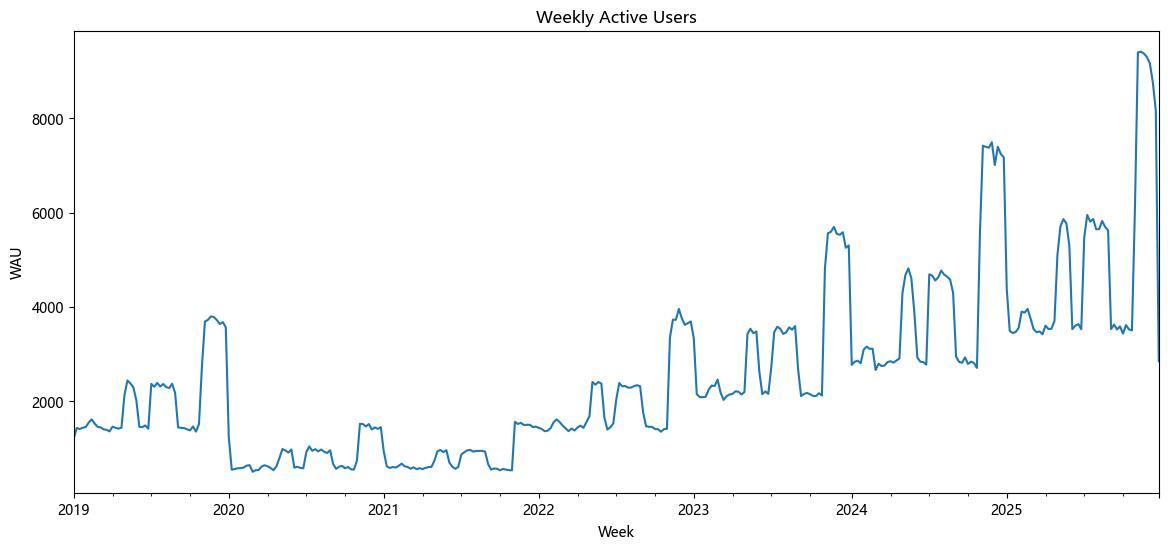

In [9]:
#WAU
#计算WAU
WAU = (user_behavior_df.groupby('order_week')['customer_unique_id']
      .nunique())

#WAU可视化
plt.figure(figsize=(14,6))
WAU.plot()
plt.title('Weekly Active Users')
plt.xlabel('Week')
plt.ylabel('WAU')
plt.show()

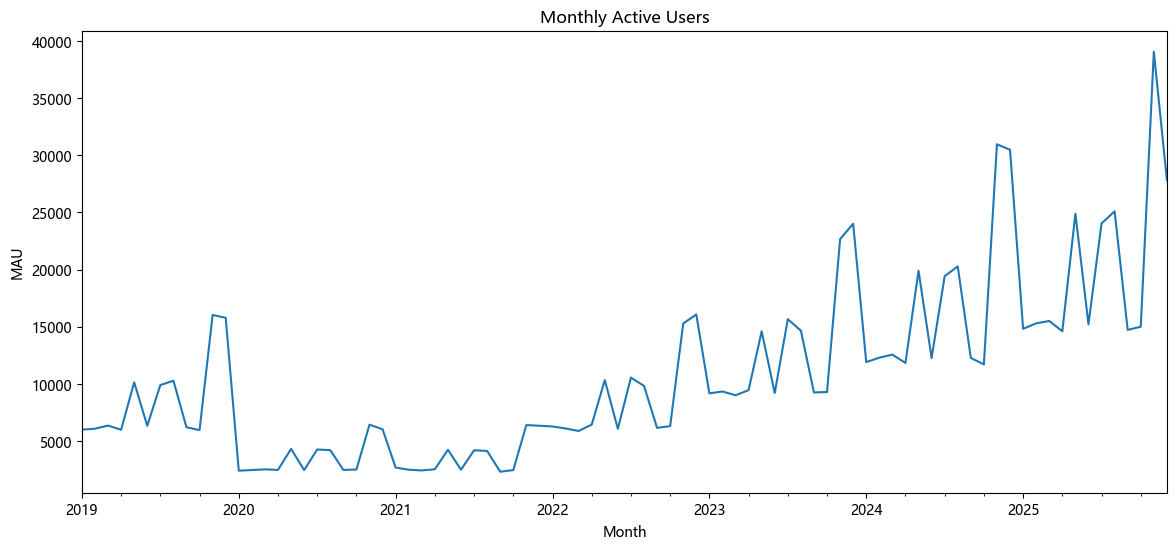

In [10]:
# MAU
MAU = user_behavior_df.groupby('order_month')['customer_unique_id'].nunique()
plt.figure(figsize=(14, 6))
MAU.plot()
plt.title('Monthly Active Users')
plt.xlabel('Month')
plt.ylabel('MAU')
plt.show()


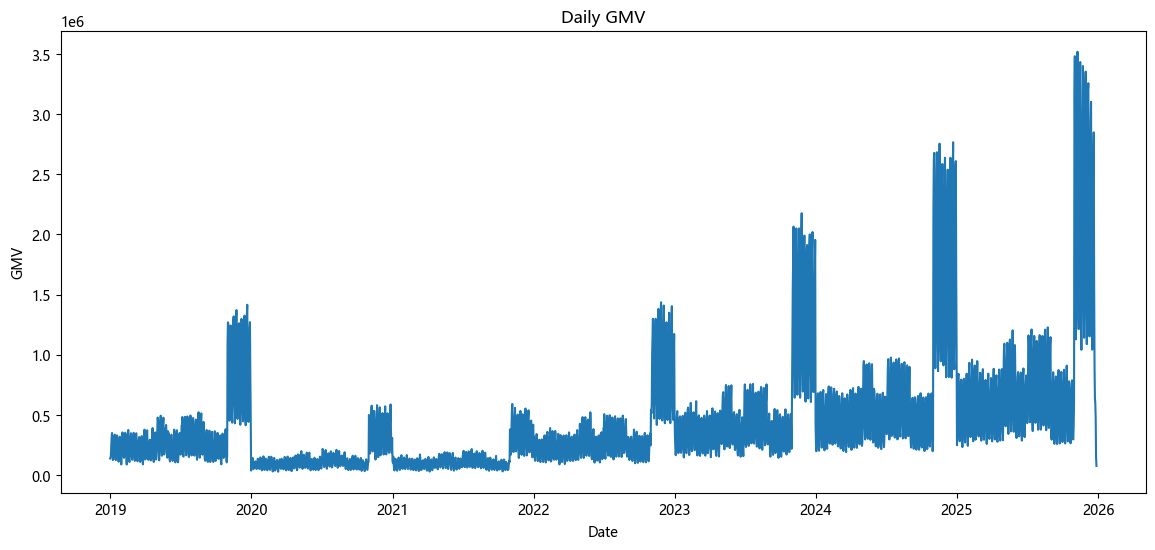

In [11]:
#计算GMV
GMV = (user_behavior_df.groupby('order_date')['payment_value']
      .sum())

#GMV可视化
plt.figure(figsize=(14,6))
GMV.plot()
plt.title('Daily GMV')
plt.xlabel('Date')
plt.ylabel('GMV')
plt.show()

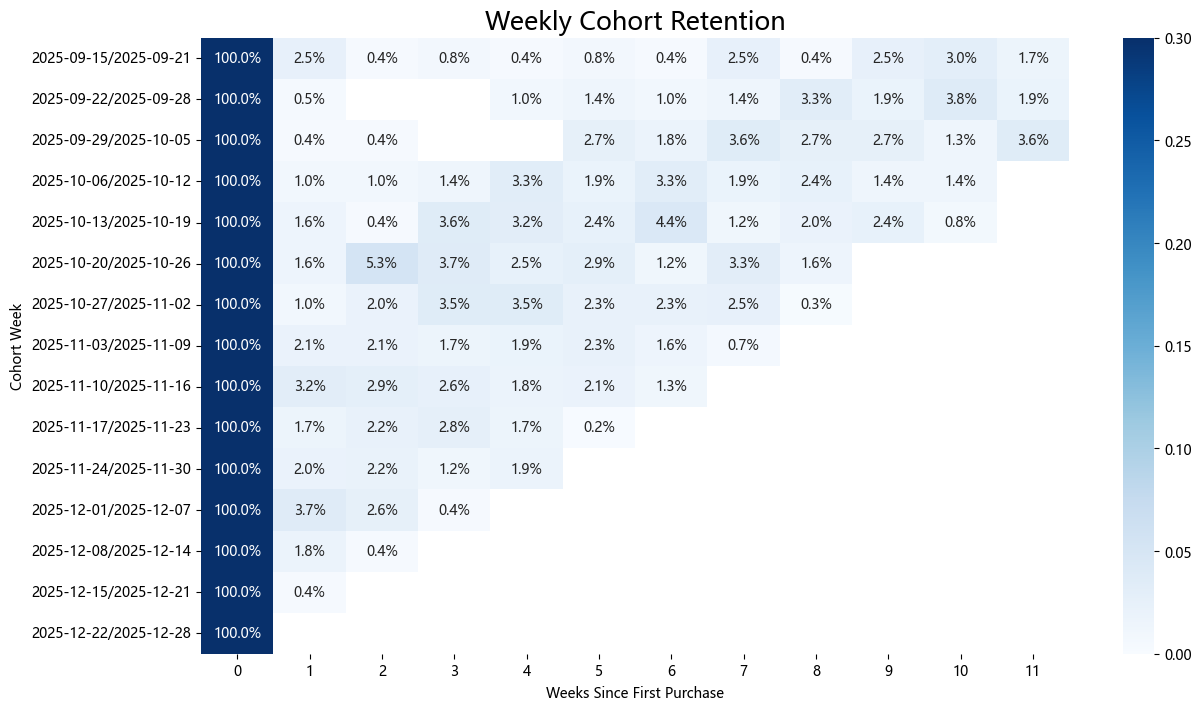

In [12]:
# 用户留存分析 按"首次购买周"分组
# 获取用户首次购买时间
first_purchase_week = (user_behavior_df.groupby('customer_unique_id')['order_purchase_timestamp']
                       .min()
                       .reset_index())

# 提取 Cohort_week（首次购买周）
first_purchase_week['cohort_week'] = (first_purchase_week['order_purchase_timestamp']
                                      .dt.to_period('W'))

# 合并回原表
cohort_week_df = user_behavior_df.merge(
    first_purchase_week[['customer_unique_id', 'cohort_week']],
    on='customer_unique_id',
    how='left')

# 提取 week_index（距首次购买过去了几周）
cohort_week_df['week_index'] = ((cohort_week_df['order_week'].dt.start_time -
                                 cohort_week_df['cohort_week'].dt.start_time)
                                .dt.days // 7)

# 统计每周留存的用户数
cohort_data = (cohort_week_df.groupby(['cohort_week', 'week_index'])['customer_unique_id']
               .nunique()
               .reset_index())

# 构建 cohort 矩阵
cohort_matrix = cohort_data.pivot(index='cohort_week',
                                  columns='week_index',
                                  values='customer_unique_id')

# 计算留存率
cohort_size = cohort_matrix.iloc[:, 0]
retention_matrix = cohort_matrix.divide(cohort_size, axis=0)

# 只看前12周（避免矩阵过宽、过于稀疏、有大量NaN值）
retention_matrix = retention_matrix.iloc[:, :12]

# 删除最前面异常cohort（数据集起始阶段可能存在用户历史行为缺失）
retention_matrix = retention_matrix.iloc[2:]

# 绘制热力图
retention_plot = retention_matrix.tail(15)
plt.figure(figsize=(14, 8))
sns.heatmap(retention_plot, annot=True, fmt='.1%', cmap='Blues', vmin=0, vmax=0.3)
plt.title('Weekly Cohort Retention', fontsize=18)
plt.xlabel('Weeks Since First Purchase')
plt.ylabel('Cohort Week')
plt.show()

购买次数分别是
1     49406
2     59577
3     55379
4     42562
5     29178
6     18094
7     10579
8      5676
9      2878
10     1505
11      632
12      321
13      132
14       62
15       29
16        6
17        1
Name: order_count, dtype: int64
购买次数的占比是
1     0.178996
2     0.215845
3     0.200636
4     0.154201
5     0.105711
6     0.065554
7     0.038327
8     0.020564
9     0.010427
10    0.005453
11    0.002290
12    0.001163
13    0.000478
14    0.000225
15    0.000105
16    0.000022
17    0.000004
Name: order_count, dtype: float64


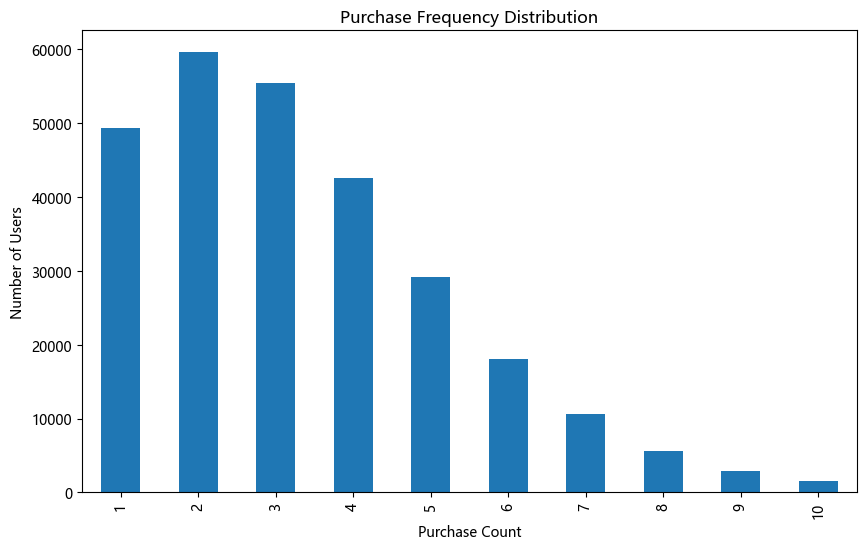

In [13]:
#用户复购分析
#统计每个用户订单数
user_order_count = (user_behavior_df.groupby('customer_unique_id')['order_id']
                   .nunique()
                   .reset_index())
user_order_count.columns = ['customer_unique_id', 'order_count']

#统计购买次数分布
purchase_distribution = (user_order_count['order_count']
                        .value_counts()
                        .sort_index())
print('购买次数分别是')
print(purchase_distribution)

#计算购买次数占比
purchase_ratio = (purchase_distribution / purchase_distribution.sum())
print('购买次数的占比是')
print(purchase_ratio)

#占比可视化
plt.figure(figsize=(10,6))
purchase_distribution[:10].plot(kind='bar')
plt.title('Purchase Frequency Distribution')
plt.xlabel('Purchase Count')
plt.ylabel('Number of Users')
plt.show()

In [14]:
# 用户流失分析：先找出每位用户最近一次购买时间
# 每位用户只保留其最后一次已完成订单的下单时间。
last_purchase = (
    user_behavior_df.groupby('customer_unique_id')['order_purchase_timestamp']
    .max()
    .reset_index(name='last_purchase_at')
)

# 快照日设为数据中最后一次下单的次日。
snapshot_date = user_behavior_df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)
last_purchase['days_since_last_purchase'] = (
    snapshot_date - last_purchase['last_purchase_at']
).dt.days

print(f'数据快照日：{snapshot_date.date()}')
display(last_purchase.head())


数据快照日：2025-12-29


,customer_unique_id,last_purchase_at,days_since_last_purchase
0,00000ce0-2e08-4b89-ba86-0c8698b2d4fb,2025-04-28 09:45:33,245
1,00004453-ecfa-4c25-94f1-0004cc58286f,2024-05-11 11:31:12,597
2,000062e5-a9a0-4056-a54d-5cf0b2473fda,2025-11-03 19:05:00,56
3,000076de-9d04-4ae8-af41-2f8caf66c899,2025-08-17 11:44:11,134
4,00008df1-f9ce-487d-b5a6-68e6992e025a,2025-11-07 18:32:12,52


流失判定规则：超过 90 天未购买
流失用户数：201,485 人
未流失用户数：74,532 人
用户流失率：73.00%


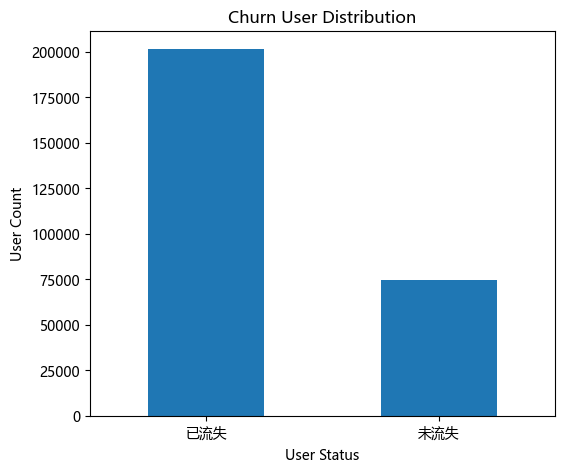

In [15]:
# 定义流失：超过 90 天未购买的用户视为流失用户
CHURN_THRESHOLD_DAYS = 90
last_purchase['is_churn'] = (
    last_purchase['days_since_last_purchase'] > CHURN_THRESHOLD_DAYS
)

churn_rate = last_purchase['is_churn'].mean()
churn_user_count = last_purchase['is_churn'].sum()
retained_user_count = (~last_purchase['is_churn']).sum()

print(f'流失判定规则：超过 {CHURN_THRESHOLD_DAYS} 天未购买')
print(f'流失用户数：{churn_user_count:,} 人')
print(f'未流失用户数：{retained_user_count:,} 人')
print(f'用户流失率：{churn_rate:.2%}')

plt.figure(figsize=(6, 5))
last_purchase['is_churn'].value_counts().rename({False: '未流失', True: '已流失'}).plot(kind='bar')
plt.title('Churn User Distribution')
plt.xlabel('User Status')
plt.ylabel('User Count')
plt.xticks(rotation=0)
plt.show()


In [16]:
# 计算 AOV（用户累计已完成订单支付金额 / 用户已完成订单数）
user_analysis = (
    user_behavior_df.groupby('customer_unique_id')
    .agg(order_count=('order_id', 'nunique'), total_spent=('payment_value', 'sum'))
    .reset_index()
)
user_analysis['AOV'] = user_analysis['total_spent'] / user_analysis['order_count']
user_analysis.head()


,customer_unique_id,order_count,total_spent,AOV
0,00000ce0-2e08-4b89-ba86-0c8698b2d4fb,2,1293.01,646.505000
1,00004453-ecfa-4c25-94f1-0004cc58286f,2,989.29,494.645000
2,000062e5-a9a0-4056-a54d-5cf0b2473fda,1,3519.90,3519.900000
3,000076de-9d04-4ae8-af41-2f8caf66c899,5,11962.73,2392.546000
4,00008df1-f9ce-487d-b5a6-68e6992e025a,7,8766.77,1252.395714


In [17]:
# 合并流失标签与用户价值指标，比较流失与未流失用户
churn_analysis = last_purchase.merge(
    user_analysis,
    on='customer_unique_id',
    how='left',
    validate='one_to_one'
)
churn_comparison = churn_analysis.groupby('is_churn').agg(
    user_count=('customer_unique_id', 'size'),
    avg_order_count=('order_count', 'mean'),
    avg_total_spent=('total_spent', 'mean'),
    avg_AOV=('AOV', 'mean')
)
display(churn_comparison)


,user_count,avg_order_count,avg_total_spent,avg_AOV
is_churn,,,,
False,74532,4.350467,5567.883536,1311.450263
True,201485,3.025034,3566.708987,1178.763771


In [18]:
#用户生命周期价值分析
#查看分布
user_analysis['total_spent'].describe()

count    276017.000000
mean       4107.079839
std        3290.564070
min          15.610000
25%        1732.790000
50%        3357.900000
75%        5636.300000
max       35992.280000
Name: total_spent, dtype: float64

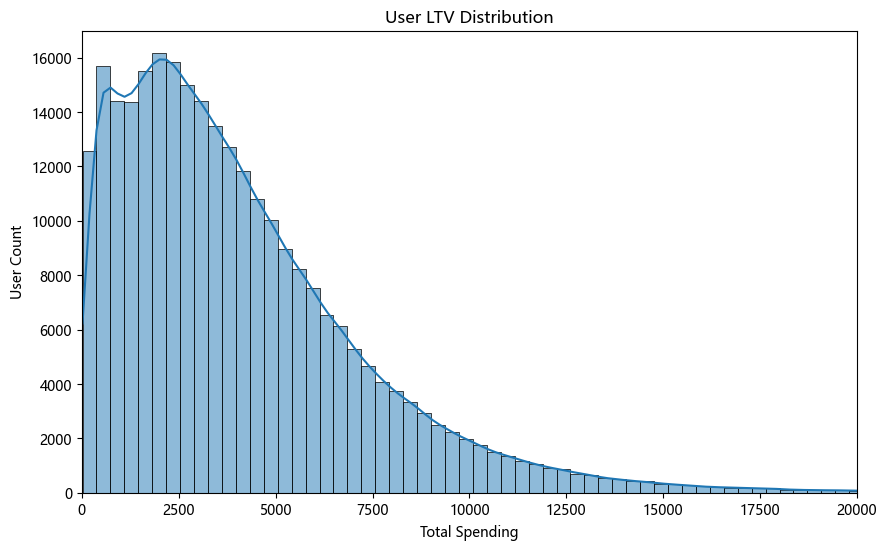

In [19]:
# LTV分布图
plt.figure(figsize=(10, 6))
sns.histplot(user_analysis['total_spent'], bins=100, kde=True)  # kde=True 保留那条拟合曲线
plt.xlim(0, 20000)
plt.title('User LTV Distribution')
plt.xlabel('Total Spending')
plt.ylabel('User Count')
plt.show()

In [20]:
# 定义高价值用户（累计消费前 10%）
threshold = user_analysis['total_spent'].quantile(0.9)
user_analysis['high_value_user'] = user_analysis['total_spent'] >= threshold
GMV_contribution = user_analysis.groupby('high_value_user')['total_spent'].sum()
GMV_ratio = GMV_contribution / GMV_contribution.sum()
print(f'高价值用户门槛：{threshold:.2f}')
print('高价值用户 GMV 贡献：')
print(GMV_ratio)


高价值用户门槛：8332.65
高价值用户 GMV 贡献：
high_value_user
False    0.723921
True     0.276079
Name: total_spent, dtype: float64


In [21]:
# 商品类目与预估商品毛利分析
# 预估商品毛利 = 含折后商品收入 - 商品成本；不计运费、履约和营销费用。
items = pd.read_csv(
    'Dataset_Customer/order_items.csv',
    usecols=['order_id', 'product_id', 'price', 'freight_value', 'discount_rate']
)
products = pd.read_csv(
    'Dataset_Customer/products.csv',
    usecols=['product_id', 'product_category_name', 'cost']
)
item_financial_df = (
    user_behavior_df[['order_id']]
    .merge(items, on='order_id', how='inner', validate='one_to_many')
    .merge(products, on='product_id', how='left', validate='many_to_one')
)
item_financial_df['product_category_name'] = item_financial_df['product_category_name'].fillna('Unknown')
item_financial_df['net_item_revenue'] = item_financial_df['price'] * (1 - item_financial_df['discount_rate'])
item_financial_df['estimated_gross_profit'] = item_financial_df['net_item_revenue'] - item_financial_df['cost']
category_kpi = (
    item_financial_df.groupby('product_category_name')
    .agg(
        item_count=('order_id', 'size'),
        order_count=('order_id', 'nunique'),
        net_item_revenue=('net_item_revenue', 'sum'),
        product_cost=('cost', 'sum'),
        estimated_gross_profit=('estimated_gross_profit', 'sum')
    )
    .reset_index()
)
category_kpi['estimated_gross_margin'] = (
    category_kpi['estimated_gross_profit'] / category_kpi['net_item_revenue']
)
category_kpi = category_kpi.sort_values('net_item_revenue', ascending=False)
display(category_kpi.head(15))
# 地域分析只需订单级收入，聚合后释放商品明细以控制内存。
order_revenue_df = item_financial_df.groupby('order_id', as_index=False).agg(
    net_item_revenue=('net_item_revenue', 'sum')
)
del item_financial_df, items, products


,product_category_name,item_count,order_count,net_item_revenue,product_cost,estimated_gross_profit,estimated_gross_margin
2,electronics,636233,469466,6.756272e+08,5.526303e+08,1.229970e+08,0.182049
4,furniture,184558,170479,1.023011e+08,6.070178e+07,4.159928e+07,0.406636
3,fashion,446008,357636,5.944739e+07,2.394641e+07,3.550098e+07,0.597183
5,home_goods,295559,260447,3.177202e+07,1.612852e+07,1.564350e+07,0.492367
0,auto,73712,71467,1.987573e+07,1.477263e+07,5.103102e+06,0.256750
6,toys,234241,205526,1.184077e+07,5.293751e+06,6.547021e+06,0.552922
1,books,183776,169845,5.397792e+06,3.246627e+06,2.151165e+06,0.398527


In [22]:
# 地域分析：按客户所在州汇总已完成订单和商品收入
order_region_df = (
    orders.loc[
        orders['order_status'].eq(valid_order_status),
        ['order_id', 'customer_id']
    ]
    .merge(
        customers[['customer_id', 'customer_unique_id', 'customer_state', 'customer_city']],
        on='customer_id', how='left', validate='one_to_one'
    )
    .merge(order_revenue_df, on='order_id', how='left', validate='one_to_one')
)
regional_kpi = (
    order_region_df.groupby('customer_state')
    .agg(
        user_count=('customer_unique_id', 'nunique'),
        order_count=('order_id', 'nunique'),
        net_item_revenue=('net_item_revenue', 'sum')
    )
    .sort_values('net_item_revenue', ascending=False)
)
display(regional_kpi.head(10))
del order_region_df, order_revenue_df


,user_count,order_count,net_item_revenue
customer_state,,,
CA,69381,234813,2.278754e+08
TX,52366,177110,1.721252e+08
FL,38028,128960,1.251734e+08
NY,34840,117269,1.141345e+08
PA,23441,78979,7.659496e+07
IL,23028,77778,7.543465e+07
GA,17402,59161,5.746103e+07
CO,5933,20247,1.940598e+07
WA,5833,19941,1.919647e+07


In [23]:
# 物流时效分析：仅使用有签收时间和预计送达时间的已完成订单
delivery_df = orders.loc[
    orders['order_status'].eq(valid_order_status),
    ['order_id', 'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']
].copy()
for column in ['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']:
    delivery_df[column] = pd.to_datetime(delivery_df[column])
delivery_df = delivery_df.dropna(subset=['order_delivered_customer_date', 'order_estimated_delivery_date'])
delivery_df['delivery_days'] = (
    delivery_df['order_delivered_customer_date'] - delivery_df['order_purchase_timestamp']
).dt.total_seconds() / 86400
delivery_df['late_days'] = (
    delivery_df['order_delivered_customer_date'] - delivery_df['order_estimated_delivery_date']
).dt.total_seconds() / 86400
late_delivery_rate = (delivery_df['late_days'] > 0).mean()
print(f'延迟送达率：{late_delivery_rate:.2%}')
display(delivery_df[['delivery_days', 'late_days']].describe(percentiles=[.5, .75, .9, .95]))


延迟送达率：9.86%


,delivery_days,late_days
count,933748.000000,933748.000000
mean,7.780634,-1.309977
std,3.667132,2.086633
min,3.006944,-2.000000
50%,7.086111,-2.000000
75%,9.017361,-2.000000
90%,11.020139,-2.000000
95%,16.410417,5.000000
max,26.415972,5.000000


In [24]:
# 评价分析：先聚合到订单粒度，避免一笔订单存在多条评价时重复计算
reviews = pd.read_csv(
    'Dataset_Customer/order_reviews.csv',
    usecols=['order_id', 'review_score']
)
review_by_order = (
    reviews.groupby('order_id', as_index=False)
    .agg(review_score=('review_score', 'mean'), review_record_count=('review_score', 'size'))
)
order_review_df = user_behavior_df[['order_id']].merge(
    review_by_order, on='order_id', how='left', validate='one_to_one'
)
review_coverage = order_review_df['review_score'].notna().mean()
review_distribution = order_review_df['review_score'].value_counts(normalize=True).sort_index()
print(f'已完成订单评价覆盖率：{review_coverage:.2%}')
print('评价得分占比：')
print(review_distribution)
del reviews, review_by_order, order_review_df


已完成订单评价覆盖率：100.00%
评价得分占比：
1.0    0.049058
2.0    0.123481
3.0    0.073706
4.0    0.251137
5.0    0.502617
Name: review_score, dtype: float64


In [25]:
# 支付偏好分析：支付方式不是获客渠道，不能用于渠道归因
payment_type_kpi = (
    payments.groupby('payment_type')
    .agg(payment_record_count=('order_id', 'size'), payment_value=('payment_value', 'sum'))
    .sort_values('payment_value', ascending=False)
)
payment_type_kpi['payment_value_share'] = payment_type_kpi['payment_value'] / payment_type_kpi['payment_value'].sum()
display(payment_type_kpi)
print('数据集中未提供 channel、source 或 campaign 字段，因此不能开展获客渠道效果或渠道 ROI 分析。')


,payment_record_count,payment_value,payment_value_share
payment_type,,,
credit_card,536416,6.202207e+08,0.507469
paypal,181278,1.937069e+08,0.158492
apple_pay,92114,1.188029e+08,0.097205
bank_transfer,96766,9.424293e+07,0.077110
voucher,123150,9.180730e+07,0.075117
debit_card,91034,8.851094e+07,0.072420
boleto,28613,1.489299e+07,0.012186


数据集中未提供 channel、source 或 campaign 字段，因此不能开展获客渠道效果或渠道 ROI 分析。
